# Práctica 9: Análisis de Texto

Para esta práctica se usan los títulos de las canciones como datos de texto. Primero se limpian, después se cuentan las palabras que más se repiten y por último se revisa qué tan largos son los títulos y se genera una nube de palabras.

In [1]:
import os
import re
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

PATH_INPUT = "../data/processed/spotify_cleaned.csv"
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Carga de datos

Igual que en las prácticas anteriores se deja una sola fila por canción (uri), de esta forma un título que estuvo muchas semanas en las listas no se cuenta varias veces.

In [2]:
df = pd.read_csv(PATH_INPUT)
canciones = df.drop_duplicates("uri").copy()
print(f"Canciones únicas: {len(canciones)}")
print(canciones["track_name"].head(10).tolist())

Canciones únicas: 2445
['good 4 u', 'deja vu', 'traitor', 'drivers license', 'favorite crime', 'Heat Waves', 'MONTERO (Call Me By Your Name)', 'Astronaut In The Ocean', 'brutal', 'happier']


## Limpieza del texto

Muchos títulos traen cosas como (feat. ...), (with ...) o - Remastered 20XX que no son parte del nombre de la canción, solo indican colaboraciones o versiones. Antes de quitarlos se cuenta cuántos títulos tienen una colaboración, después se pasa todo a minúsculas, se quitan los paréntesis y todo lo que va después de  un  "-" o de "feat", los apóstrofes y cualquier carácter que no sea letra o número también se quita. También hay unos títulos con las letras separadas por espacios como "a p p l y i n g . p r e s s u r e", para eso se les van a juntar las letras para que no cuenten como muchas palabras de una letra.

In [3]:
canciones["colaboracion"] = canciones["track_name"].str.contains(r"\bfeat\b|\bft\.|[\(\[]with ", case=False)
print(f"Títulos con feat o with: {canciones['colaboracion'].sum()} ({canciones['colaboracion'].mean():.1%})")

Títulos con feat o with: 533 (21.8%)


In [4]:
def limpiar(titulo):
    titulo = titulo.lower()
    # quitar lo que esta entre parentesis o corchetes
    titulo = re.sub(r"\(.*?\)|\[.*?\]", "", titulo)
    # quitar versiones tipo " - remastered 2011"
    titulo = titulo.split(" - ")[0]
    titulo = titulo.split(" feat")[0]
    # algunos titulos vienen con letras separadas como "a p p l y i n g . p r e s s u r e"
    if re.match(r"^\w \w \w\b", titulo):
        titulo = titulo.replace(" ", "")
    titulo = re.sub(r"['’‘]", "", titulo)
    titulo = re.sub(r"[^a-z0-9\s]", " ", titulo)
    return titulo.strip()

canciones["titulo_limpio"] = canciones["track_name"].apply(limpiar)
canciones[["track_name", "titulo_limpio"]].sample(8, random_state=1)

,track_name,titulo_limpio
45053,Melody,melody
15827,h u n g e r . o n . h i l l s i d e (with Bas),hunger on hillside
416,As It Was,as it was
14233,Sway My Way (with Amy Shark),sway my way
3622,Visiting Hours,visiting hours
1005,Therefore I Am,therefore i am
39892,Belly Dancer,belly dancer
10555,WAP (feat. Megan Thee Stallion),wap


## Palabras vacías

Muchos títulos tienen palabras que no dicen nada de la canción y que si se dejan serian de las palabras que más se repiten. Por ejemplo **"the", "you" o "and"**, que son las mas comunes. Además se usa la lista que trae `wordcloud` para eliminar esas palabras y se agregan algunas más que quedaron después de quitar los apóstrofes como: *dont*, *im*, etc.

In [5]:
stopwords = STOPWORDS | {"dont", "im", "ill", "cant", "aint", "youre", "ive", "thats", "feat", "remix"}

palabras = []
for titulo in canciones["titulo_limpio"]:
    for p in titulo.split():
        if p not in stopwords and len(p) > 1:
            palabras.append(p)

conteo = Counter(palabras)
print(f"Palabras totales: {len(palabras)}")
print(f"Palabras distintas: {len(conteo)}")
print(f"Palabras que aparecen una sola vez: {sum(1 for v in conteo.values() if v == 1)}")

Palabras totales: 3967
Palabras distintas: 1847
Palabras que aparecen una sola vez: 1136


## Análisis exploratorio

Palabras más frecuentes:

love         84
christmas    64
go           33
good         20
back         20
time         20
let          19
night        19
know         18
little       18
home         17
heart        16
way          16
life         16
one          16
last         15
girl         14
day          14
want         14
baby         14
dtype: int64


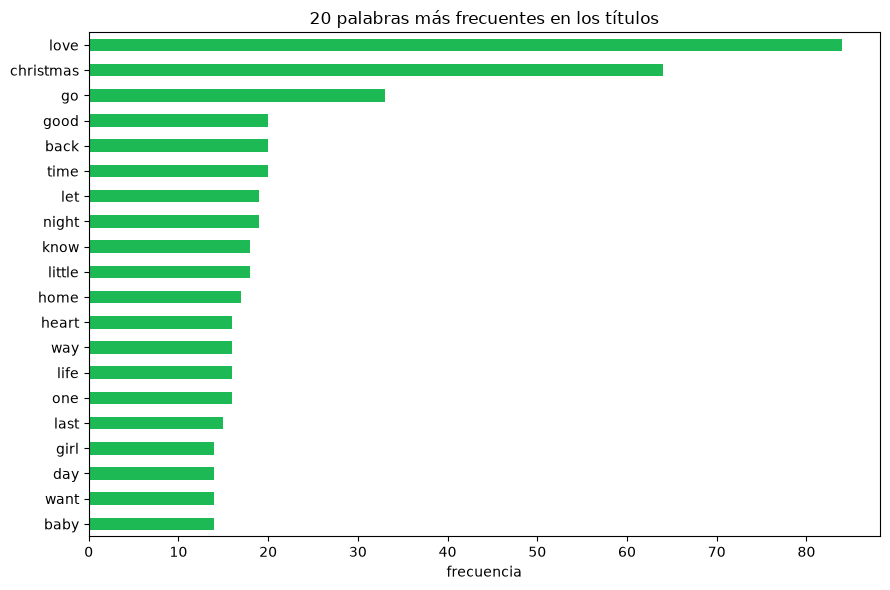

In [6]:
top = pd.Series(dict(conteo.most_common(20)))
print(top)

fig, ax = plt.subplots(figsize=(9, 6))
top[::-1].plot(kind="barh", ax=ax, color="#1DB954")
ax.set_xlabel("frecuencia")
ax.set_title("20 palabras más frecuentes en los títulos")

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "palabras_frecuentes.png"), dpi=150)
plt.show()

### Largo de los títulos

Se cuenta cuántas palabras tiene cada título ya limpio (sin quitar stopwords, para medir el título completo).

In [7]:
canciones["num_palabras"] = canciones["titulo_limpio"].str.split().str.len()
print(canciones["num_palabras"].describe().round(2))
print(f"Títulos de una palabra: {(canciones['num_palabras'] == 1).mean():.1%}")
print(f"Títulos de 3 palabras o menos: {(canciones['num_palabras'] <= 3).mean():.1%}")

# titulos mas largos
print(canciones.sort_values("num_palabras", ascending=False)["titulo_limpio"].head(5).tolist())

count    2445.00
mean        2.42
std         1.34
min         0.00
25%         1.00
50%         2.00
75%         3.00
max         9.00
Name: num_palabras, dtype: float64
Títulos de una palabra: 28.8%
Títulos de 3 palabras o menos: 82.0%
['you took the words right out of my mouth', 'and to those i love  thanks for sticking around', 'let it snow  let it snow  let it snow', 'let it snow  let it snow  let it snow', 'its beginning to look a lot like christmas']


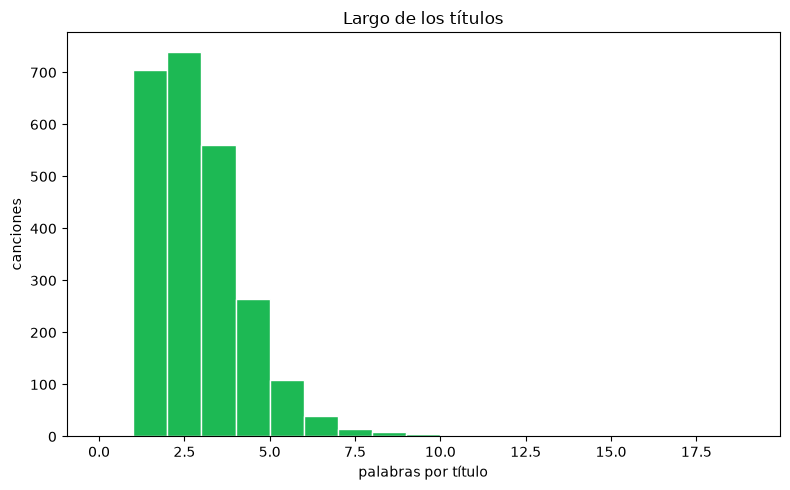

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(canciones["num_palabras"], bins=range(0, 20), color="#1DB954", edgecolor="white")
ax.set_xlabel("palabras por título")
ax.set_ylabel("canciones")
ax.set_title("Largo de los títulos")

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "largo_titulos.png"), dpi=150)
plt.show()

## Nube de palabras

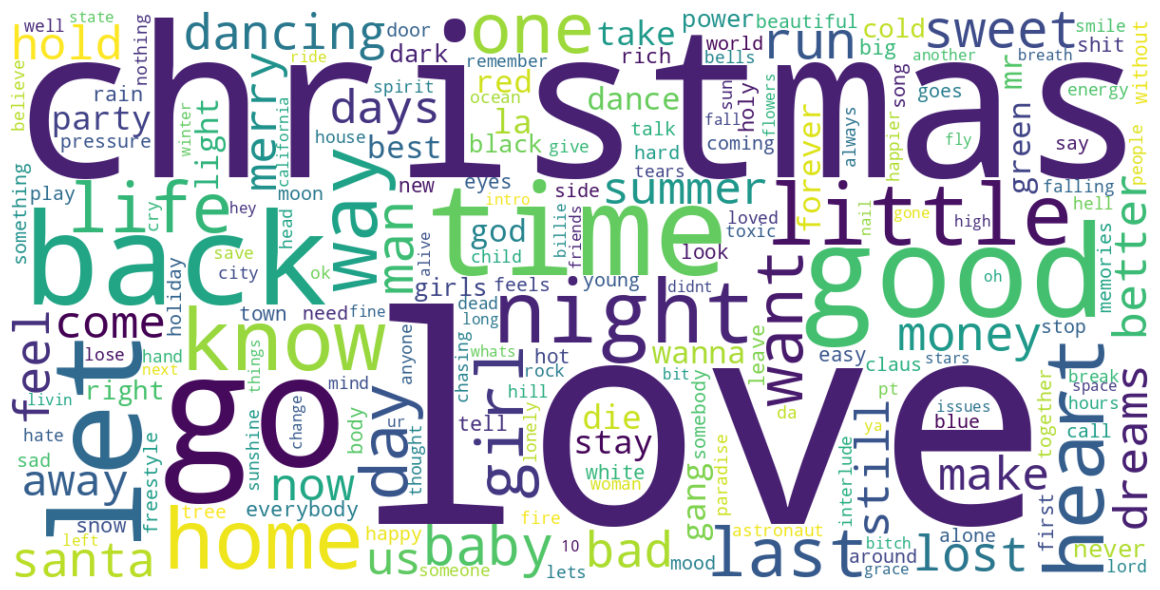

In [9]:
nube = WordCloud(width=1200, height=600, background_color="white", colormap="viridis", random_state=42)
nube.generate_from_frequencies(conteo)

fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(nube, interpolation="bilinear")
ax.axis("off")

fig.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, "nube_palabras.png"), dpi=150)
plt.show()

De las 2445 canciones se quedaron 3967 palabras útiles, de las cuales 1847 son distintas y 1136 aparecen una sola vez. Es decir, la mayoría de las palabras de los títulos casi no se repiten y solo unas cuantas aparecen muchas veces.

La palabra más usada es **love** (84 veces), algo esperado porque el amor es el tema más común en la música pop. La segunda es **christmas** (64) y junto con *santa*, *merry*, *snow*, *holiday* o *bells* se ve que las canciones navideñas tienen bastante presencia en las listas, lo que coincide con los picos de streams en diciembre que se vieron en la práctica 8. El resto de las palabras frecuentes (*good*, *night*, *home*, *heart*, *life*, *baby*, *girl*) son temas de relaciones y sentimientos, y aparecen también palabras como *money*, *gang* o *party* que vienen más del rap y el hip hop.

En cuanto al largo, los títulos son cortos, con una mediana de 2 palabras, el 29% tiene una sola palabra y el 82% tiene 3 palabras o menos (este 82% ya incluye al 29% de una palabra). Los más largos son en su mayoría canciones navideñas (*let it snow let it snow let it snow*, *its beginning to look a lot like christmas*). Aparte de eso, el 21.8% de los títulos menciona una colaboración con `feat`, `ft.` o `with`, lo que muestra que las colaboraciones son bastante comunes en las canciones que llegan a las listas.

La nube de palabras resume de forma visual: *love* y *christmas* destacan sobre todo lo demás y las palabras más pequeñas reflejan la variedad de temas en los títulos.